<a href="https://colab.research.google.com/github/Joel-Vijo/intro_to_git/blob/master/cpu_vs_gpu_monte_carlo_var.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CPU vs GPU: Monte Carlo Value-at-Risk

**Goal:** show *when* and *why* a GPU beats a CPU, using a workload from finance: portfolio VaR via correlated Monte Carlo.

**Plan**
1. Define the simulation once, written so the *same code* runs on NumPy (CPU) and CuPy (GPU)
2. Check correctness (both give the same VaR within Monte Carlo error)
3. Benchmark: runtime vs. number of scenarios, assets, and horizon
4. Look at where the GPU does **not** help (small sizes, transfer overhead)
5. Float32 vs float64

> **Colab setup:** `Runtime -> Change runtime type -> T4 GPU`, then `Runtime -> Run all`.
> The notebook still runs on CPU-only runtimes (GPU sections are skipped).

## 0. Setup

In [1]:
import subprocess, time, math, random, statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import cupy as cp
    cp.cuda.runtime.getDeviceCount()
    HAS_GPU = True
except Exception as e:
    cp = None
    HAS_GPU = False
    print("No usable GPU/CuPy found:", e)

print("NumPy:", np.__version__)
if HAS_GPU:
    props = cp.cuda.runtime.getDeviceProperties(0)
    print("CuPy :", cp.__version__)
    print("GPU  :", props["name"].decode(), f"| {props['totalGlobalMem']/1e9:.1f} GB")
else:
    print("Switch the Colab runtime to a GPU to see the comparison.")

import os
print("CPU cores available:", os.cpu_count())

NumPy: 2.4.6
CuPy : 14.0.1
GPU  : Tesla T4 | 15.6 GB
CPU cores available: 2


## 1. The workload

We simulate `n_scen` scenarios of `horizon` daily returns for `n_assets` correlated assets:

1. Build a covariance matrix and take its **Cholesky factor** `L`
2. Draw independent normals `Z`, correlate them: `R = Z @ L.T + mu`
3. Convert returns to per-asset P&L with a nonlinear transform (`expm1`), so the work can't be algebraically collapsed into a single vector
4. Portfolio P&L per scenario = weighted sum over assets, summed over the horizon
5. **VaR** = the loss at the `alpha` quantile, **CVaR** = mean loss beyond it

Every scenario is independent, so this is *embarrassingly parallel*: ideal for a GPU.

The function takes `xp` (either `numpy` or `cupy`). **The algorithm is identical; only where it runs changes.**
Scenarios are processed in chunks so that large runs fit in memory.

In [2]:
def make_portfolio(n_assets, seed=42, dtype=np.float32):
    # Built on the host in float64 for determinism, then cast. Same inputs for CPU and GPU.
    rng = np.random.default_rng(seed)
    B = rng.standard_normal((n_assets, 5))                  # 5 latent risk factors
    cov = B @ B.T + np.diag(rng.uniform(0.5, 1.5, n_assets))
    d = np.sqrt(np.diag(cov))
    corr = cov / np.outer(d, d)
    vol = rng.uniform(0.01, 0.03, n_assets)                  # 1-3% daily vol
    cov = corr * np.outer(vol, vol)
    L = np.linalg.cholesky(cov)
    mu = rng.uniform(-0.0002, 0.0005, n_assets)
    w = np.full(n_assets, 1.0 / n_assets)
    return L.astype(dtype), mu.astype(dtype), w.astype(dtype)


def var_mc(xp, L, mu, w, n_scen, horizon=1, alpha=0.01, seed=0,
           dtype=np.float32, chunk_elems=1.5e8):
    # L, mu, w must already live on the device that xp refers to.
    n_assets = L.shape[0]
    rng = xp.random.default_rng(seed)
    chunk = max(1, int(chunk_elems // (n_assets * horizon)))
    pnl = xp.empty(n_scen, dtype=dtype)
    LT = L.T.copy()
    for s in range(0, n_scen, chunk):
        m = min(chunk, n_scen - s)
        Z = rng.standard_normal((m * horizon, n_assets), dtype=dtype)   # random numbers made ON the device
        R = Z @ LT + mu                                                  # correlate (big matmul)
        asset_pnl = xp.expm1(R)                                          # nonlinear transform
        daily = asset_pnl @ w                                            # portfolio daily P&L
        pnl[s:s + m] = daily.reshape(m, horizon).sum(axis=1)
    k = int(alpha * n_scen)
    q = xp.partition(pnl, k)[k]                                          # alpha-quantile without a full sort
    var = -q
    cvar = -pnl[pnl <= q].mean()
    return float(var), float(cvar)

## 2. Correctness check
Before timing anything, verify CPU and GPU agree. They use different random number generators, so we expect agreement within Monte Carlo error, not bit-for-bit equality.

In [3]:
n_assets, n_scen = 100, 2_000_000
L, mu, w = make_portfolio(n_assets)

var_cpu, cvar_cpu = var_mc(np, L, mu, w, n_scen)
print(f"CPU : VaR(99%) = {var_cpu:.5f}   CVaR = {cvar_cpu:.5f}")

if HAS_GPU:
    Lg, mug, wg = cp.asarray(L), cp.asarray(mu), cp.asarray(w)
    var_gpu, cvar_gpu = var_mc(cp, Lg, mug, wg, n_scen)
    print(f"GPU : VaR(99%) = {var_gpu:.5f}   CVaR = {cvar_gpu:.5f}")
    rel = abs(var_gpu - var_cpu) / var_cpu
    print(f"Relative difference in VaR: {rel:.3%}")
    assert rel < 0.02, "CPU and GPU VaR disagree more than expected"

CPU : VaR(99%) = 0.00321   CVaR = 0.00370
GPU : VaR(99%) = 0.00321   CVaR = 0.00371
Relative difference in VaR: 0.004%


## 3. The strawman: pure Python loops

Included only to show the worst case. It is **not** a fair baseline. The fair CPU baseline is vectorized NumPy (which also uses multithreaded BLAS for the matmul).

In [4]:
def var_pure_python(L, mu, w, n_scen, alpha=0.01, seed=0):
    rnd = random.Random(seed)
    n = len(mu)
    Ll, mul, wl = L.tolist(), mu.tolist(), w.tolist()
    pnl = []
    for _ in range(n_scen):
        z = [rnd.gauss(0, 1) for _ in range(n)]
        total = 0.0
        for i in range(n):
            r = mul[i] + sum(Ll[i][j] * z[j] for j in range(i + 1))
            total += wl[i] * math.expm1(r)
        pnl.append(total)
    pnl.sort()
    return -pnl[int(alpha * n_scen)]

A_small, N_small = 50, 5_000
Ls, mus, ws = make_portfolio(A_small)

t = time.perf_counter(); v_py = var_pure_python(Ls, mus, ws, N_small); t_py = time.perf_counter() - t
t = time.perf_counter(); v_np, _ = var_mc(np, Ls, mus, ws, N_small); t_np = time.perf_counter() - t
print(f"Pure Python: {t_py:.3f}s   NumPy: {t_np:.5f}s   -> NumPy is {t_py/t_np:,.0f}x faster")
print(f"(5,000 scenarios x 50 assets. At 10 million scenarios pure Python would need ~{t_py*10_000_000/N_small/3600:.1f} hours)")

Pure Python: 0.730s   NumPy: 0.00533s   -> NumPy is 137x faster
(5,000 scenarios x 50 assets. At 10 million scenarios pure Python would need ~0.4 hours)


## 4. Benchmark harness

Two things people commonly get wrong with GPU benchmarks, handled here:

- **Asynchronous execution:** GPU calls return immediately. We call `synchronize()` before stopping the clock, otherwise we'd time the *launch*, not the *work*.
- **Warm-up:** the first GPU call pays for CUDA context creation and kernel compilation, so we run a small throwaway call first.

We report the **median of several runs**.

In [5]:
def sync():
    if HAS_GPU:
        cp.cuda.Stream.null.synchronize()

def timeit(fn, reps=3):
    times = []
    for _ in range(reps):
        sync()
        t = time.perf_counter()
        fn()
        sync()
        times.append(time.perf_counter() - t)
    return statistics.median(times)

def bench(n_scen, n_assets, horizon=1, run_cpu=True, run_gpu=True, dtype=np.float32):
    L, mu, w = make_portfolio(n_assets, dtype=dtype)
    reps = 5 if n_scen * n_assets * horizon < 1e7 else 3 if n_scen * n_assets * horizon < 1e9 else 1
    row = {"n_scen": n_scen, "n_assets": n_assets, "horizon": horizon}
    if run_cpu:
        row["cpu_s"] = timeit(lambda: var_mc(np, L, mu, w, n_scen, horizon, dtype=dtype), reps)
    if run_gpu and HAS_GPU:
        Lg, mug, wg = cp.asarray(L), cp.asarray(mu), cp.asarray(w)
        var_mc(cp, Lg, mug, wg, min(n_scen, 10_000), horizon, dtype=dtype)   # warm-up
        row["gpu_s"] = timeit(lambda: var_mc(cp, Lg, mug, wg, n_scen, horizon, dtype=dtype), reps)
        row["speedup"] = row["cpu_s"] / row["gpu_s"] if run_cpu else np.nan
    return row

# warm-up GPU once so the first benchmark row isn't polluted by CUDA init
if HAS_GPU:
    _L, _m, _w = make_portfolio(10)
    var_mc(cp, cp.asarray(_L), cp.asarray(_m), cp.asarray(_w), 1000)
    sync()

## 5. Experiment A: scale the number of scenarios

This is the main result. Expect the CPU to be competitive (or even faster) at small sizes, because of GPU launch overhead, then the GPU to pull away as the problem grows.

> Set `MAX_EXP = 8` to include 100 million scenarios. The CPU run at that size takes several minutes.

In [6]:
MAX_EXP = 7           # scenarios go up to 10**MAX_EXP (set to 8 for the 100M run)
N_ASSETS = 100

rows = []
for e in range(3, MAX_EXP + 1):
    r = bench(10**e, N_ASSETS)
    rows.append(r)
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})

df_scen = pd.DataFrame(rows)
df_scen

{'n_scen': 1000, 'n_assets': 100, 'horizon': 1, 'cpu_s': 0.0029, 'gpu_s': 0.0037, 'speedup': 0.7705}
{'n_scen': 10000, 'n_assets': 100, 'horizon': 1, 'cpu_s': 0.0243, 'gpu_s': 0.0042, 'speedup': 5.7828}
{'n_scen': 100000, 'n_assets': 100, 'horizon': 1, 'cpu_s': 0.2444, 'gpu_s': 0.0075, 'speedup': 32.7734}
{'n_scen': 1000000, 'n_assets': 100, 'horizon': 1, 'cpu_s': 2.1421, 'gpu_s': 0.0398, 'speedup': 53.8545}
{'n_scen': 10000000, 'n_assets': 100, 'horizon': 1, 'cpu_s': 23.614, 'gpu_s': 0.3061, 'speedup': 77.1376}


,n_scen,n_assets,horizon,cpu_s,gpu_s,speedup
0,1000,100,1,0.002887,0.003747,0.770491
1,10000,100,1,0.024280,0.004199,5.782803
2,100000,100,1,0.244385,0.007457,32.773440
3,1000000,100,1,2.142086,0.039775,53.854502
4,10000000,100,1,23.613955,0.306128,77.137550


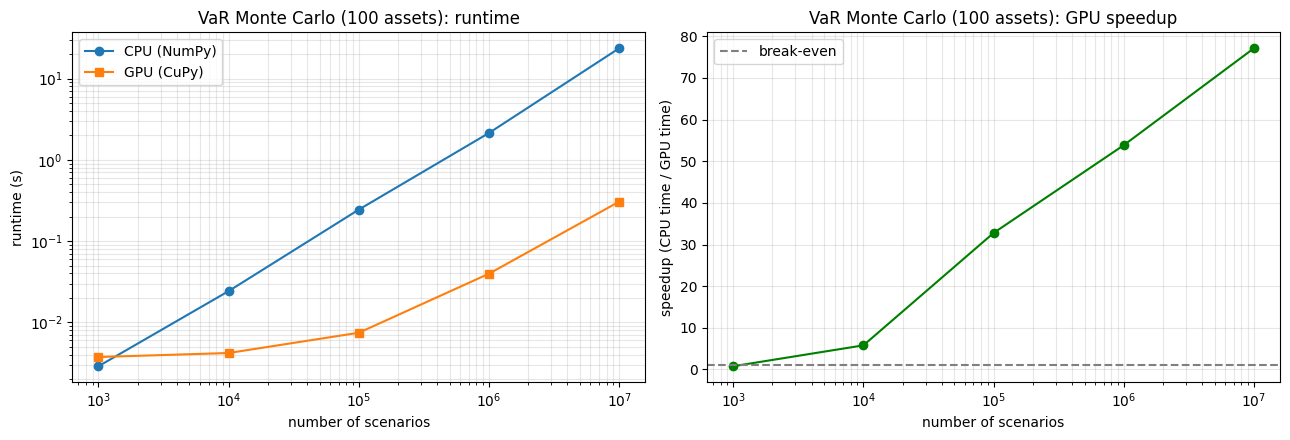

In [7]:
def plot_scaling(df, xcol, xlabel, title):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].loglog(df[xcol], df["cpu_s"], "o-", label="CPU (NumPy)")
    if "gpu_s" in df:
        ax[0].loglog(df[xcol], df["gpu_s"], "s-", label="GPU (CuPy)")
    ax[0].set_xlabel(xlabel); ax[0].set_ylabel("runtime (s)"); ax[0].set_title(title + ": runtime")
    ax[0].grid(True, which="both", alpha=0.3); ax[0].legend()
    if "speedup" in df:
        ax[1].semilogx(df[xcol], df["speedup"], "o-", color="green")
        ax[1].axhline(1, color="gray", ls="--", label="break-even")
        ax[1].set_xlabel(xlabel); ax[1].set_ylabel("speedup (CPU time / GPU time)")
        ax[1].set_title(title + ": GPU speedup"); ax[1].grid(True, which="both", alpha=0.3); ax[1].legend()
    else:
        ax[1].text(0.5, 0.5, "No GPU detected", ha="center"); ax[1].axis("off")
    plt.tight_layout(); plt.show()

plot_scaling(df_scen, "n_scen", "number of scenarios", f"VaR Monte Carlo ({N_ASSETS} assets)")

**How to read it:** the left plot is log-log, so the gap between the lines is the speedup. The right plot makes the break-even point visible: the left side shows where the GPU's fixed overheads dominate, the right side shows where its parallelism pays off.

## 6. Experiment B: scale the number of assets
More assets means a larger matrix multiply (`scenarios x assets` times `assets x assets`). Matmul is exactly what GPUs are built for, so the speedup should grow with asset count.

 n_scen  n_assets  horizon   cpu_s  gpu_s  speedup
1000000        10        1  0.2587 0.0086  30.1068
1000000        50        1  1.3542 0.0264  51.2572
1000000       100        1  2.0907 0.0396  52.7800
1000000       250        1  6.8527 0.0945  72.5228
1000000       500        1 14.6635 0.2241  65.4352
1000000      1000        1 39.5588 0.7450  53.1016


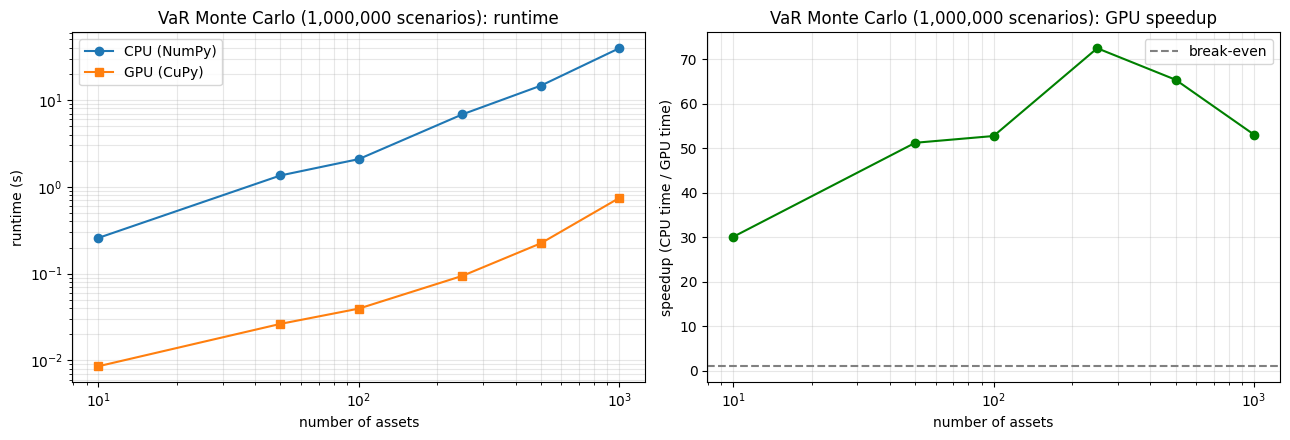

In [8]:
N_SCEN_B = 1_000_000
rows = [bench(N_SCEN_B, a) for a in [10, 50, 100, 250, 500, 1000]]
df_assets = pd.DataFrame(rows)
print(df_assets.round(4).to_string(index=False))
plot_scaling(df_assets, "n_assets", "number of assets", f"VaR Monte Carlo ({N_SCEN_B:,} scenarios)")

## 7. Experiment C: multi-day paths
Simulating a 10-day or 250-day horizon multiplies the amount of work per scenario by the horizon length. (Scenarios are reduced here to keep the CPU run reasonable.)

 n_scen  n_assets  horizon   cpu_s  gpu_s  speedup
 100000       100        1  0.2432 0.0039  62.1203
 100000       100       10  2.1260 0.0286  74.3481
 100000       100       50 11.1100 0.1216  91.3494
 100000       100      250 55.0442 0.5521  99.7053


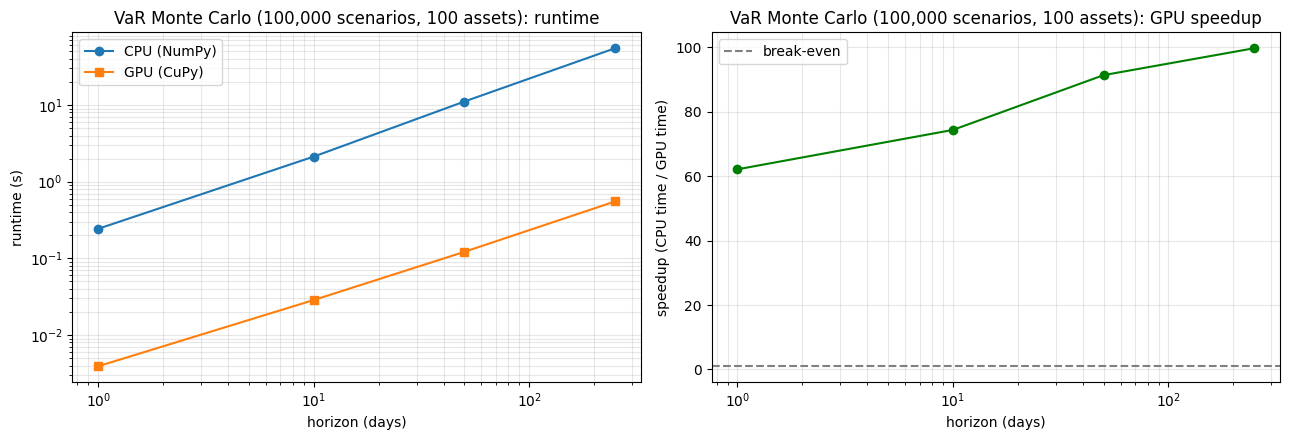

In [9]:
N_SCEN_C, A_C = 100_000, 100
rows = [bench(N_SCEN_C, A_C, horizon=h) for h in [1, 10, 50, 250]]
df_h = pd.DataFrame(rows)
print(df_h.round(4).to_string(index=False))
plot_scaling(df_h, "horizon", "horizon (days)", f"VaR Monte Carlo ({N_SCEN_C:,} scenarios, {A_C} assets)")

## 8. Where the transfer cost bites

In the experiments above, the only inputs are a small covariance factor and weights, and random numbers are generated **on the device**, so almost no data crosses the PCIe bus.

Many real pipelines instead start with data on the host (e.g. historical scenario matrices). Then host-to-device copy time becomes part of the cost. Here we measure it directly.

Data size                 : 800 MB
Host -> device copy      :    231.2 ms
GPU compute only         :     37.1 ms
GPU end-to-end (copy+compute):    268.3 ms
CPU (NumPy)              :   1313.9 ms

Speedup compute-only: 35.4x | end-to-end: 4.9x


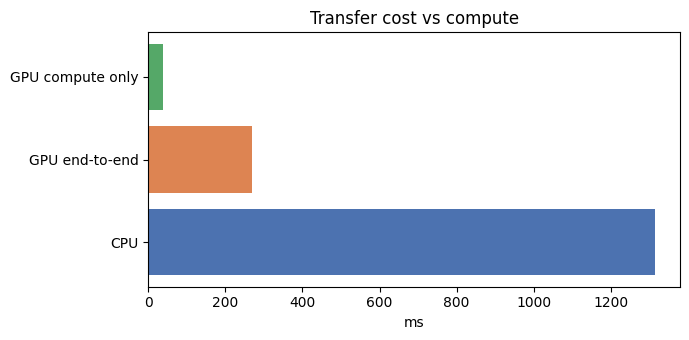

In [10]:
if HAS_GPU:
    n_scen, n_assets = 2_000_000, 100
    L, mu, w = make_portfolio(n_assets)
    H = np.random.default_rng(1).standard_normal((n_scen, n_assets)).astype(np.float32)   # "historical" shocks on host
    Lg, mug, wg = cp.asarray(L), cp.asarray(mu), cp.asarray(w)

    def gpu_compute_only(Hg):
        R = Hg @ Lg.T + mug
        return float(-cp.quantile(cp.expm1(R) @ wg, 0.01))

    Hg = cp.asarray(H); sync(); gpu_compute_only(Hg)          # warm-up

    t_h2d = timeit(lambda: cp.asarray(H))
    t_comp = timeit(lambda: gpu_compute_only(Hg))
    t_cpu = timeit(lambda: float(-np.quantile(np.expm1(H @ L.T + mu) @ w, 0.01)))
    t_e2e = t_h2d + t_comp

    print(f"Data size                 : {H.nbytes/1e6:.0f} MB")
    print(f"Host -> device copy      : {t_h2d*1e3:8.1f} ms")
    print(f"GPU compute only         : {t_comp*1e3:8.1f} ms")
    print(f"GPU end-to-end (copy+compute): {t_e2e*1e3:8.1f} ms")
    print(f"CPU (NumPy)              : {t_cpu*1e3:8.1f} ms")
    print(f"\nSpeedup compute-only: {t_cpu/t_comp:.1f}x | end-to-end: {t_cpu/t_e2e:.1f}x")

    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.barh(["CPU", "GPU end-to-end", "GPU compute only"], [t_cpu*1e3, t_e2e*1e3, t_comp*1e3], color=["#4c72b0", "#dd8452", "#55a868"])
    ax.set_xlabel("ms"); ax.set_title("Transfer cost vs compute"); plt.tight_layout(); plt.show()
else:
    print("Skipped (no GPU).")

## 9. Precision: float32 vs float64

Consumer and cloud-inference GPUs (like the Colab T4) have far more float32 throughput than float64, often by 30x or more. CPUs lose only about 2x going to float64. So the dtype you choose changes the comparison. A fair benchmark compares like with like, and this cell shows the effect.

In [11]:
rows = []
for dt, name in [(np.float32, "float32"), (np.float64, "float64")]:
    r = bench(1_000_000, 100, dtype=dt); r["dtype"] = name; rows.append(r)
df_prec = pd.DataFrame(rows)[["dtype", "cpu_s", "gpu_s", "speedup"] if HAS_GPU else ["dtype", "cpu_s"]]
print(df_prec.round(4).to_string(index=False))

  dtype  cpu_s  gpu_s  speedup
float32 2.5163 0.0397  63.3640
float64 2.9984 0.1998  15.0055


## 10. Summary table

In [12]:
summary = df_scen.copy()
summary["n_scen"] = summary["n_scen"].map(lambda x: f"{x:,}")
cols = ["n_scen", "cpu_s"] + (["gpu_s", "speedup"] if HAS_GPU else [])
print(summary[cols].round(4).to_string(index=False))
if HAS_GPU:
    best = df_scen.loc[df_scen["speedup"].idxmax()]
    print(f"\nPeak speedup in Experiment A: {best['speedup']:.1f}x at {int(best['n_scen']):,} scenarios")

    n_scen   cpu_s  gpu_s  speedup
     1,000  0.0029 0.0037   0.7705
    10,000  0.0243 0.0042   5.7828
   100,000  0.2444 0.0075  32.7734
 1,000,000  2.1421 0.0398  53.8545
10,000,000 23.6140 0.3061  77.1376

Peak speedup in Experiment A: 77.1x at 10,000,000 scenarios


## 11. Takeaways

- **The algorithm didn't change.** The same function ran on both devices; only `xp` changed.
- **GPUs win on throughput, not latency.** At small sizes, launch and synchronization overhead make the GPU slower or equal. At millions of scenarios it wins decisively.
- **More parallel work = bigger win.** Speedup grew with asset count (bigger matmuls) and with horizon length.
- **Data movement is the hidden cost.** Generating random numbers on the device avoided PCIe transfers. When inputs start on the host, copy time can eat much of the gain.
- **Precision matters.** float64 narrows the gap on GPUs with weak fp64 throughput.

**Why it works:** a CPU has a few powerful cores tuned for low latency and branching code. A GPU has thousands of simpler cores tuned for running the *same* operation over huge amounts of independent data, which is exactly what Monte Carlo is.

**Caveats for an honest benchmark:** the CPU baseline here is NumPy with multithreaded BLAS on a small number of Colab cores. A many-core server CPU narrows the gap, and so does a hand-tuned multithreaded implementation. Also, timings vary with hardware, so quote the GPU model and CPU core count alongside any speedup number.

### Ideas to extend
- Add a **Numba `@njit(parallel=True)`** CPU version as a stronger baseline
- Try **PyTorch CUDA** and compare against CuPy
- Add **antithetic variates** or **quasi-random (Sobol)** sampling to reduce variance, and show variance vs. runtime
- Price an option portfolio inside each scenario to make the per-scenario work heavier